## Description

This notebook was created to complete the challenges presented at the end of each lesson in the course **Pandas: Getting to Know the Library**

### Exercises:
The ML team has come forward with a few last-minute requests for us to address during this exploratory analysis phase. These requests are:

1) Calculate the average number of rooms for the properties;

2) Determine the number of unique neighborhoods in our dataset;

3) Analyze which neighborhoods have the highest average rental prices;

4) Create a horizontal bar chart showing the 5 neighborhoods with the highest average rental prices.

## Lesson 2: Exploratory data analysis

For the challenges in this lesson, we will use the same dataset that we are employing for the development of our project. Therefore, in the cell below, we will import this dataset and apply the transformations that have been carried out up to this point—as of lesson 2.

In [1]:
import pandas as pd

In [2]:
# importing the database
url = 'https://raw.githubusercontent.com/alura-cursos/pandas-conhecendo-a-biblioteca/main/base-de-dados/aluguel.csv'
data = pd.read_csv(url, sep=';')

In [3]:
commercial_properties = ['Conjunto Comercial/Sala',
                      'Prédio Inteiro', 'Loja/Salão',
                      'Galpão/Depósito/Armazém',
                      'Casa Comercial', 'Terreno Padrão',
                      'Loja Shopping/ Ct Comercial',
                      'Box/Garagem', 'Chácara',
                      'Loteamento/Condomínio', 'Sítio',
                      'Pousada/Chalé', 'Hotel', 'Indústria']

# removing commercial properties
df = data.query('@commercial_properties not in Tipo')

# selecting only properties of the apartment type
df = df.query('Tipo == "Apartamento"')

# viewing the database
df.head()

,Tipo,Bairro,Quartos,Vagas,Suites,Area,Valor,Condominio,IPTU
3,Apartamento,Centro,1,0,0,15,800.0,390.0,20.0
4,Apartamento,Higienópolis,1,0,0,48,800.0,230.0,NaN
5,Apartamento,Vista Alegre,3,1,0,70,1200.0,NaN,NaN
6,Apartamento,Cachambi,2,0,0,50,1300.0,301.0,17.0
10,Apartamento,Centro,1,0,0,36,1200.0,NaN,NaN


### Challenge 1
Calculate the average number of rooms per apartment

In [4]:
df.groupby('Tipo')['Quartos'].mean()

,Quartos
Tipo,
Apartamento,2.481569


### Challenge 2
Determine how many unique neighborhoods exist in our database

In [5]:
len(df['Bairro'].unique())

149

In [6]:
df['Bairro'].nunique()


149

### Challenge 3
Analyze which neighborhoods have the highest average rental prices

In [7]:
data.groupby('Bairro')[['Valor']].mean().sort_values('Valor', ascending=False)

,Valor
Bairro,
Jacarepaguá,314143.489637
Irajá,154610.470588
Caju,120264.782609
Vasco da Gama,120000.000000
Cidade Nova,88166.692308
...,...
Inhoaíba,738.888889
Turiaçu,733.333333
Magalhães Bastos,726.666667


### Challenge 4
Create a horizontal bar chart showing the 5 neighborhoods with the highest average rental prices.

In [8]:
df_neighborhoods = data.groupby('Bairro')[['Valor']].mean().sort_values('Valor', ascending=False).head(5)

<Axes: ylabel='Bairro'>

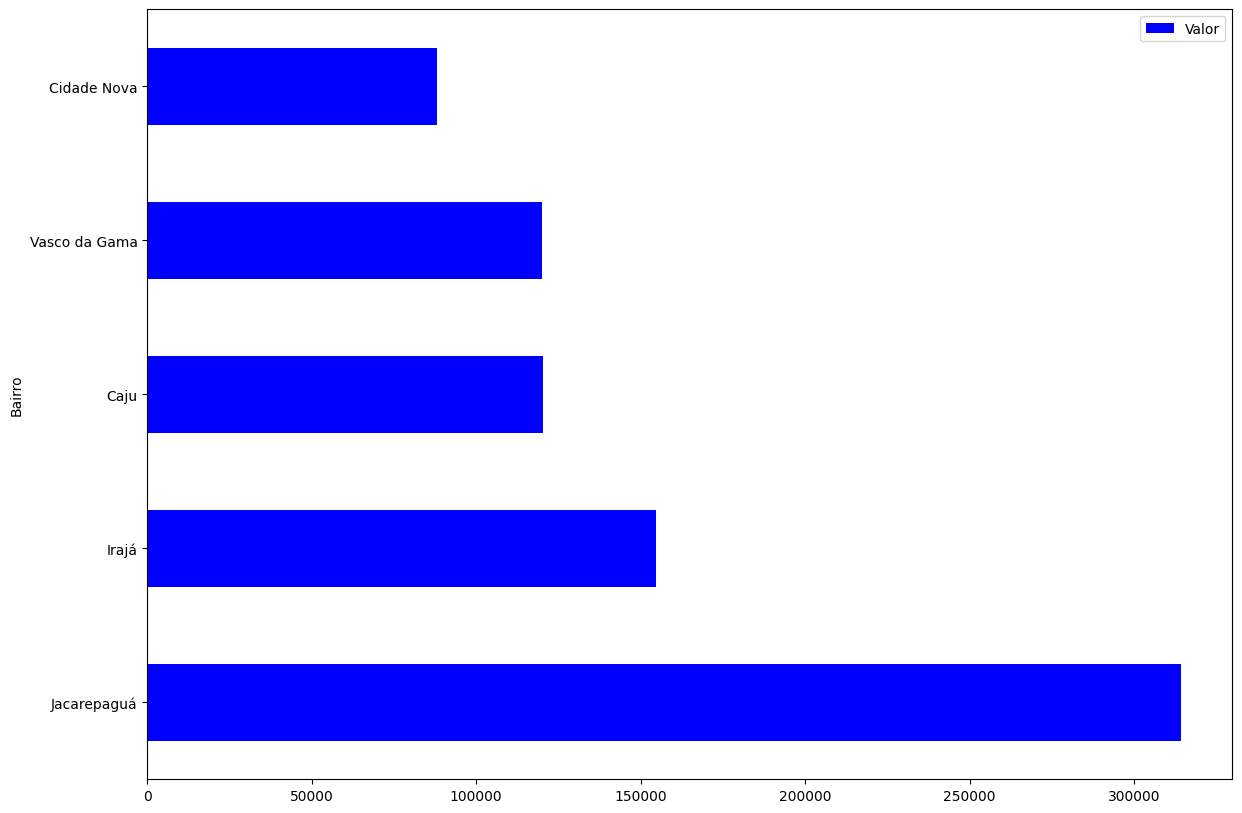

In [9]:
df_neighborhoods.plot(kind='barh', figsize=(14, 10), color='blue')